# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

,liczba,odsetek_%
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


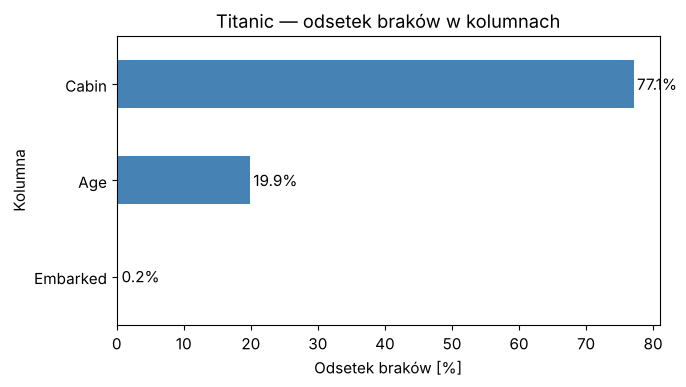

In [2]:
braki = titanic.isna().sum()
tabela_brakow = pd.DataFrame({
    "liczba": braki,
    "odsetek_%": (titanic.isna().mean() * 100).round(2),
})
tabela_brakow = tabela_brakow[tabela_brakow["liczba"] > 0].sort_values("liczba", ascending=False)
display(tabela_brakow)

ax = tabela_brakow["odsetek_%"].sort_values().plot.barh(color="steelblue")
ax.set_xlabel("Odsetek braków [%]")
ax.set_ylabel("Kolumna")
ax.set_title("Titanic — odsetek braków w kolumnach")
for i, v in enumerate(tabela_brakow["odsetek_%"].sort_values()):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

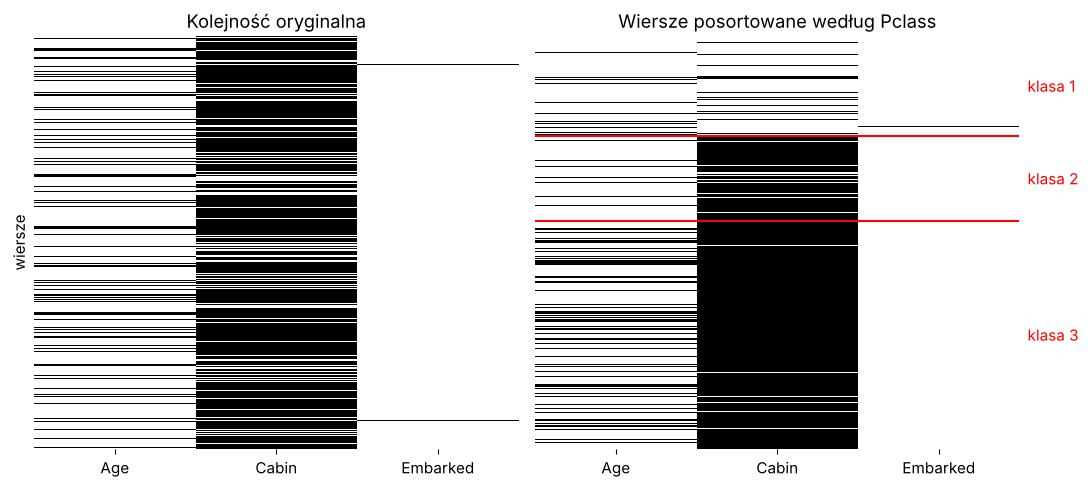

Odsetek braków Cabin w klasach:
Pclass
1    0.185
2    0.913
3    0.976
Name: Cabin, dtype: float64


In [3]:
kolumny = ["Age", "Cabin", "Embarked"]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sns.heatmap(titanic[kolumny].isna(), cbar=False, ax=axes[0], yticklabels=False, cmap="Greys")
axes[0].set_title("Kolejność oryginalna")
axes[0].set_ylabel("wiersze")

posort = titanic.sort_values("Pclass").reset_index(drop=True)
sns.heatmap(posort[kolumny].isna(), cbar=False, ax=axes[1], yticklabels=False, cmap="Greys")
axes[1].set_title("Wiersze posortowane według Pclass")
# granice klas na wykresie
granice = posort["Pclass"].value_counts().sort_index().cumsum()
for g in granice[:-1]:
    axes[1].axhline(g, color="red", lw=1.5)
for klasa, (pocz, kon) in zip([1, 2, 3], zip([0, *granice[:-1]], granice)):
    axes[1].text(3.05, (pocz + kon) / 2, f"klasa {klasa}", va="center", color="red")
plt.tight_layout()
plt.show()

print("Odsetek braków Cabin w klasach:")
print(titanic["Cabin"].isna().groupby(titanic["Pclass"]).mean().round(3))

*Twoja odpowiedź:* Na pierwszym wykresie braki `Cabin` wyglądają na rozsiane przypadkowo po całym zbiorze. Po posortowaniu według klasy widać wyraźną strukturę: w 1. klasie numer kabiny jest znany dla większości pasażerów (brak tylko ok. 19%), a w 2. i 3. klasie brakuje go prawie zawsze (ok. 91% i 98%). Braki `Cabin` zależą więc od klasy — nie są losowe (to co najmniej MAR). Podobnie, choć słabiej, braki `Age` są częstsze w 3. klasie. `Embarked` ma tylko 2 braki, nie widać w nich wzorca.

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Odsetek braków wieku w klasach [%]:
 Pclass
1    13.9
2     6.0
3    27.7
Name: Age, dtype: float64 

Odsetek braków wieku wg płci [%]:
 Sex
female    16.9
male      21.5
Name: Age, dtype: float64 

Odsetek ocalałych [%]:
 Age
wiek znany    40.6
brak wieku    29.4
Name: Survived, dtype: float64


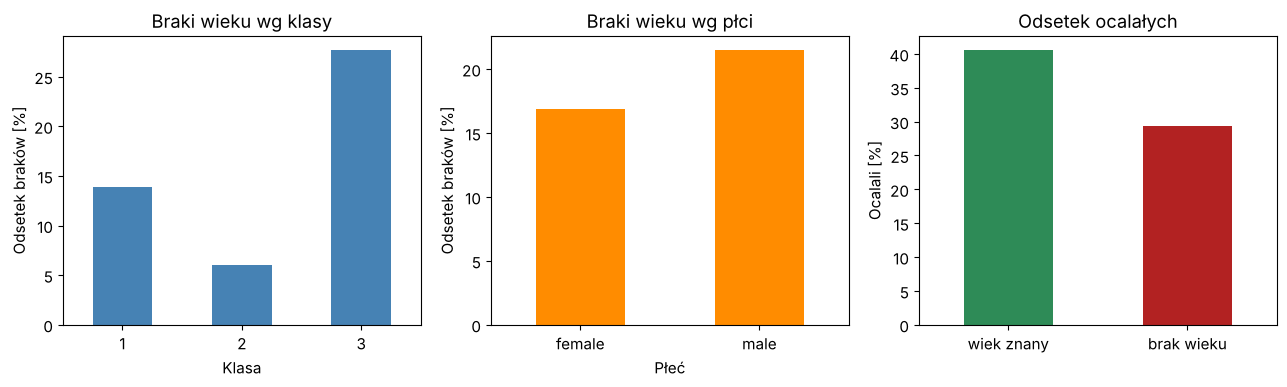

In [4]:
brak_wieku = titanic["Age"].isna()

brak_klasa = (brak_wieku.groupby(titanic["Pclass"]).mean() * 100).round(1)
brak_plec = (brak_wieku.groupby(titanic["Sex"]).mean() * 100).round(1)
przezycie = (titanic.groupby(brak_wieku)["Survived"].mean() * 100).round(1)
przezycie.index = przezycie.index.map({False: "wiek znany", True: "brak wieku"})

print("Odsetek braków wieku w klasach [%]:\n", brak_klasa, "\n")
print("Odsetek braków wieku wg płci [%]:\n", brak_plec, "\n")
print("Odsetek ocalałych [%]:\n", przezycie)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
brak_klasa.plot.bar(ax=axes[0], color="steelblue", rot=0)
axes[0].set(title="Braki wieku wg klasy", xlabel="Klasa", ylabel="Odsetek braków [%]")
brak_plec.plot.bar(ax=axes[1], color="darkorange", rot=0)
axes[1].set(title="Braki wieku wg płci", xlabel="Płeć", ylabel="Odsetek braków [%]")
przezycie.plot.bar(ax=axes[2], color=["seagreen", "firebrick"], rot=0)
axes[2].set(title="Odsetek ocalałych", xlabel="", ylabel="Ocalali [%]")
plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Braki wieku **nie są MCAR**. Ich odsetek silnie zależy od klasy: ok. 28% w 3. klasie wobec 6% w 2. i 14% w 1. Mężczyźni mają je nieco częściej niż kobiety (21% vs 17%). Do tego osoby bez wieku przeżywały rzadziej (ok. 29% vs 41%). Braki są więc powiązane z innymi zmiennymi (co najmniej MAR).

Gdybyśmy usunęli wiersze bez wieku, odsetek ocalałych wzrósłby z 38,4% do 40,6%. Wyrzucilibyśmy bowiem nieproporcjonalnie dużo pasażerów 3. klasy, którzy częściej ginęli. Zbiór stałby się „bogatszy” i bardziej „szczęśliwy” niż w rzeczywistości — wyniki byłyby obciążone.

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [5]:
warianty = {
    "bez zmian": titanic,
    "dropna(Embarked)": titanic.dropna(subset=["Embarked"]),
    "dropna(Age)": titanic.dropna(subset=["Age"]),
    "dropna() — wszystko": titanic.dropna(),
}

tabela = pd.DataFrame({
    nazwa: {
        "liczba wierszy": len(df),
        "odsetek ocalałych [%]": round(df["Survived"].mean() * 100, 1),
        "odsetek 1. klasy [%]": round((df["Pclass"] == 1).mean() * 100, 1),
    }
    for nazwa, df in warianty.items()
}).T
tabela["liczba wierszy"] = tabela["liczba wierszy"].astype(int)
tabela

,liczba wierszy,odsetek ocalałych [%],odsetek 1. klasy [%]
bez zmian,891,38.4,24.2
dropna(Embarked),889,38.2,24.1
dropna(Age),714,40.6,26.1
dropna() — wszystko,183,67.2,86.3


*Twoja odpowiedź:* Najbardziej zniekształca dane `dropna()` bez argumentów. Zostaje tylko 183 z 891 wierszy (ok. 21%). Odsetek ocalałych skacze z 38,4% do ok. 67%, a odsetek pasażerów 1. klasy z 24% do ok. 86%. Wynika to stąd, że `dropna()` usuwa każdy wiersz z brakiem `Cabin`, a numer kabiny jest znany prawie wyłącznie dla 1. klasy. W efekcie zostają głównie bogaci pasażerowie, którzy częściej przeżyli. `dropna(Embarked)` niczego nie zmienia (usuwa 2 wiersze). `dropna(Age)` zmienia wyniki umiarkowanie, ale zauważalnie (zad. 3).

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

Mediany wieku w grupach klasa × płeć:


Sex     female  male
Pclass              
1         35.0  40.0
2         28.0  30.0
3         21.5  25.0


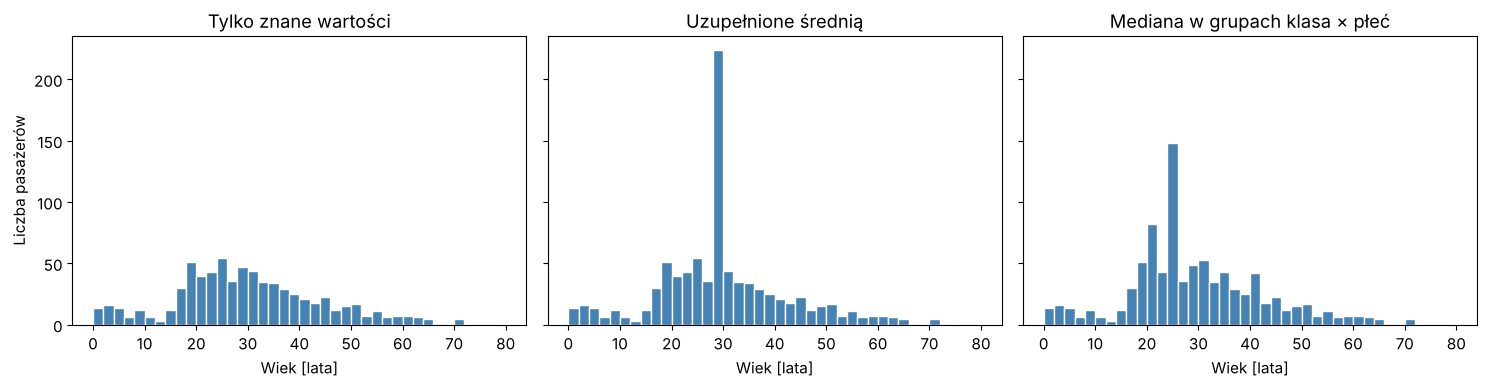

Odchylenia standardowe:
 znane wartości       14.53
średnia              13.00
mediana w grupach    13.30
dtype: float64


In [6]:
titanic["Age_brak"] = titanic["Age"].isna().astype(int)   # flaga — najpierw!

titanic["wiek_srednia"] = titanic["Age"].fillna(titanic["Age"].mean())
mediany_grup = titanic.groupby(["Pclass", "Sex"])["Age"].transform("median")
titanic["wiek_grupy"] = titanic["Age"].fillna(mediany_grup)

print("Mediany wieku w grupach klasa × płeć:")
print(titanic.groupby(["Pclass", "Sex"])["Age"].median().unstack())

bins = np.arange(0, 82, 2)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (kol, tytul) in zip(axes, [("Age", "Tylko znane wartości"),
                                   ("wiek_srednia", "Uzupełnione średnią"),
                                   ("wiek_grupy", "Mediana w grupach klasa × płeć")]):
    ax.hist(titanic[kol].dropna(), bins=bins, color="steelblue", edgecolor="white")
    ax.set(title=tytul, xlabel="Wiek [lata]")
axes[0].set_ylabel("Liczba pasażerów")
plt.tight_layout()
plt.show()

odchylenia = titanic[["Age", "wiek_srednia", "wiek_grupy"]].std().round(2)
odchylenia.index = ["znane wartości", "średnia", "mediana w grupach"]
print("Odchylenia standardowe:\n", odchylenia)

*Twoja odpowiedź:* Uzupełnienie średnią wstawia 177 identycznych wartości (ok. 29,7 roku). Na histogramie powstaje sztuczny „słup”, a odchylenie standardowe spada z ok. 14,5 do 13,0. Rozkład jest sztucznie zwężony. Mediana w grupach klasa × płeć rozkłada uzupełnione wartości na 6 różnych poziomów (od ok. 21,5 do 40 lat). Daje to mniejsze piki i odchylenie ok. 13,3, bliższe oryginałowi. Bardziej zniekształca więc **uzupełnianie średnią**. Mediana w grupach wykorzystuje też to, że wiek zależy od klasy (starsi w 1. klasie), więc jest bardziej realistyczna. Obie metody nadal zaniżają zmienność.

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

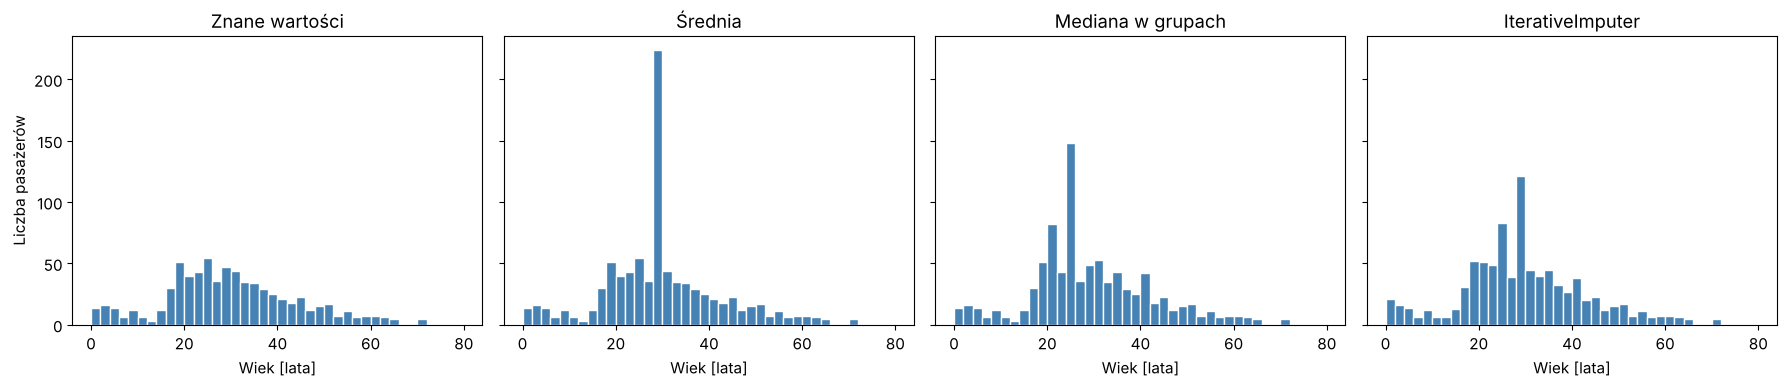

Odchylenia standardowe:
Age             14.53
wiek_srednia    13.00
wiek_grupy      13.30
wiek_model      13.52
dtype: float64

Liczba różnych wartości wstawionych w miejsce braków:
  wiek_srednia: 1
  wiek_grupy: 6
  wiek_model: 96


In [7]:
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer

X = titanic[["Age", "Pclass", "SibSp", "Parch", "Fare"]].copy()
X["Sex01"] = (titanic["Sex"] == "male").astype(int)

imputer = IterativeImputer(random_state=0, max_iter=20)
titanic["wiek_model"] = imputer.fit_transform(X)[:, 0].clip(0.42, 80)  # przytnij do sensownego zakresu

bins = np.arange(0, 82, 2)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (kol, tytul) in zip(axes, [("Age", "Znane wartości"), ("wiek_srednia", "Średnia"),
                                   ("wiek_grupy", "Mediana w grupach"), ("wiek_model", "IterativeImputer")]):
    ax.hist(titanic[kol].dropna(), bins=bins, color="steelblue", edgecolor="white")
    ax.set(title=tytul, xlabel="Wiek [lata]")
axes[0].set_ylabel("Liczba pasażerów")
plt.tight_layout()
plt.show()

print("Odchylenia standardowe:")
print(titanic[["Age", "wiek_srednia", "wiek_grupy", "wiek_model"]].std().round(2))
print("\nLiczba różnych wartości wstawionych w miejsce braków:")
for kol in ["wiek_srednia", "wiek_grupy", "wiek_model"]:
    print(f"  {kol}: {titanic.loc[titanic['Age_brak'] == 1, kol].nunique()}")

*Odpowiedź:* `IterativeImputer` przewiduje wiek z klasy, płci, liczby krewnych i ceny biletu. Każdy pasażer bez wieku dostaje więc własną wartość (96 różnych zamiast 1 lub 6). Histogram nie ma sztucznych pików, a odchylenie standardowe (ok. 13,5) jest najbliższe oryginałowi (14,5). Wartości z modelu nadal leżą bliżej „środka” niż prawdziwe dane, bo regresja zwraca wartość oczekiwaną bez szumu. Dlatego zmienność jest wciąż nieco zaniżona, choć mniej niż przy średniej (13,0) i medianie w grupach (13,3).

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [8]:
mieszkania = pd.read_csv("nieruchomosci.csv")

print("Rozmiar:", mieszkania.shape)
print("\nTypy kolumn:")
print(mieszkania.dtypes)
print("\nBraki widziane przez pandas:")
print(mieszkania.isna().sum())
print("Łącznie:", mieszkania.isna().sum().sum())

# Dlaczego powierzchnia jest tekstowa? Szukamy wartości, które nie dają się zamienić na liczbę
nieliczbowe = mieszkania.loc[pd.to_numeric(mieszkania["powierzchnia"], errors="coerce").isna()
                             & mieszkania["powierzchnia"].notna(), "powierzchnia"]
print("\nNieliczbowe wartości w 'powierzchnia':", nieliczbowe.unique())

Rozmiar: (45, 13)

Typy kolumn:
id               int64
miasto             str
dzielnica          str
powierzchnia       str
liczba_pokoi     int64
rok_budowy         str
pietro             str
liczba_pieter    int64
parking            str
balkon             str
stan               str
cena_m2          int64
cena_total       int64
dtype: object

Braki widziane przez pandas:
id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64
Łącznie: 8

Nieliczbowe wartości w 'powierzchnia': <StringArray>
['brak']
Length: 1, dtype: str


*Twoja odpowiedź:* pandas widzi tylko **8 braków**: 4 w `powierzchnia` (zapisane jako `N/A`) i 4 w `rok_budowy` (zapisane jako `NA`). To jedyne oznaczenia, które pandas rozpoznaje domyślnie. Liczbowe typy mają tylko `liczba_pokoi`, `liczba_pieter`, `cena_m2` i `cena_total`. Pozostałe kolumny są tekstowe, choć `powierzchnia`, `rok_budowy` i `pietro` powinny być liczbowe.

Kolumna `powierzchnia` jest tekstowa, bo obok liczb zawiera słowo `brak`. Wystarczy jedna wartość, której nie da się zamienić na liczbę, żeby pandas wczytał całą kolumnę jako tekst. Z tego samego powodu tekstowe są `rok_budowy` (też `brak`) i `pietro` (`brak`). Za to `cena_m2` jest liczbowa, ale ukrywa braki jako `-1` i `-999`, więc tu pandas nie podpowie nam niczego przez typ.

### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [9]:
tekstowe = mieszkania.select_dtypes(exclude="number").columns.drop(["miasto", "dzielnica"])
liczbowe = mieszkania.select_dtypes(include="number").columns.drop("id")

for kol in tekstowe:
    print(f"=== {kol} (tekstowa)")
    print(mieszkania[kol].value_counts(dropna=False).to_dict(), "\n")
for kol in liczbowe:
    print(f"=== {kol} (liczbowa)")
    print("unikalne (posortowane):", np.sort(mieszkania[kol].unique()), "\n")

# Pułapka: zera w powierzchni i piętrze
print("Wiersze z powierzchnia == '0':")
display(mieszkania.loc[mieszkania["powierzchnia"] == "0", ["id", "powierzchnia", "cena_m2", "cena_total"]])
print("Wiersze z pietro == '0':")
display(mieszkania.loc[mieszkania["pietro"] == "0", ["id", "pietro", "liczba_pieter"]])

=== powierzchnia (tekstowa)
{nan: 4, '0': 3, '48': 2, '72': 2, '55': 2, '60': 2, '70': 2, '58': 2, '62': 2, 'brak': 2, '65': 1, '80': 1, '45': 1, '90': 1, '52': 1, '68': 1, '75': 1, '50': 1, '66': 1, '85': 1, '54': 1, '95': 1, '56': 1, '42': 1, '78': 1, '88': 1, '64': 1, '51': 1, '69': 1, '46': 1, '82': 1, '76': 1} 

=== rok_budowy (tekstowa)
{nan: 4, 'brak': 3, '2015': 2, '2010': 2, '2018': 2, '2020': 2, '2019': 2, '2016': 2, '2017': 2, '2014': 2, '2011': 2, '2013': 2, '1998': 1, '2005': 1, '2001': 1, '1995': 1, '2012': 1, '2008': 1, '1999': 1, '2003': 1, '2009': 1, '2021': 1, '1997': 1, '2007': 1, '2002': 1, '1996': 1, '2006': 1, '2022': 1, '2000': 1, '2004': 1} 

=== pietro (tekstowa)
{'2': 9, '1': 8, '3': 7, '4': 6, '0': 3, '5': 3, '6': 3, '7': 2, '-999': 2, 'brak': 1, '8': 1} 

=== parking (tekstowa)
{'Tak': 34, 'Nie': 6, '?': 5} 

=== balkon (tekstowa)
{'Tak': 35, 'Nie': 7, '?': 3} 

=== stan (tekstowa)
{'Dobry': 28, 'Bardzo dobry': 11, 'Do remontu': 5, '很好': 1} 

=== liczba_poko

,id,powierzchnia,cena_m2,cena_total
13,14,0,10800,648000
28,29,0,10200,612000
41,42,0,9200,552000


Wiersze z pietro == '0':


,id,pietro,liczba_pieter
6,7,0,6
17,18,0,3
33,34,0,2


*Twoja odpowiedź:*

Oznaczenia braków w poszczególnych kolumnach:

| kolumna | oznaczenia braku |
|---|---|
| `powierzchnia` | `brak`, `N/A` (pandas rozpoznaje sam), `0` |
| `rok_budowy` | `NA` (pandas rozpoznaje sam), `brak` |
| `pietro` | `brak`, `-999` |
| `parking` | `?` |
| `balkon` | `?` |
| `cena_m2` | `-1`, `-999` |
| `stan` | brak oznaczeń braku, ale jest dziwna wartość `很好` (zad. 9) |

`liczba_pokoi`, `liczba_pieter` i `cena_total` są kompletne.

**Pułapka z zerem:** w kolumnie `powierzchnia` zero oznacza brak danych. Mieszkanie nie może mieć 0 m², a `cena_total` w tych wierszach jest dodatnia (np. 648 000 zł przy 10 800 zł/m², czyli 60 m²). W kolumnie `pietro` zero to **parter**, czyli prawdziwa wartość, zgodnie z opisem danych. Te zera występują w budynkach z 2–6 piętrami i nie towarzyszą im żadne inne anomalie. Dlatego `"0"` wolno uznać za brak tylko w kolumnie `powierzchnia`. Globalne `na_values=["0"]` skasowałoby prawdziwe parterowe mieszkania.

In [10]:
braki_slownik = {
    "powierzchnia": ["brak", "0"],          # "N/A" pandas rozpoznaje domyślnie
    "rok_budowy": ["brak"],                 # "NA" pandas rozpoznaje domyślnie
    "pietro": ["brak", "-999"],             # 0 = parter → NIE jest brakiem!
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": ["-1", "-999"],
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

print("Typy kolumn:")
print(mieszkania.dtypes)
print("\nLiczba braków:")
print(mieszkania.isna().sum())
print("Łącznie:", mieszkania.isna().sum().sum())

Typy kolumn:
id                 int64
miasto               str
dzielnica            str
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking              str
balkon               str
stan                 str
cena_m2          float64
cena_total         int64
dtype: object

Liczba braków:
id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          2
cena_total       0
dtype: int64
Łącznie: 29


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [11]:
print(mieszkania["stan"].value_counts(dropna=False))
display(mieszkania.loc[mieszkania["stan"] == "很好"])

# Porównanie z innymi mieszkaniami: rok budowy i cena za m² w każdej kategorii stanu
display(mieszkania.groupby("stan")[["rok_budowy", "cena_m2"]].median())

mieszkania["stan"] = mieszkania["stan"].replace({"很好": "Bardzo dobry"})
print("Po poprawce:")
print(mieszkania["stan"].value_counts(dropna=False))

stan
Dobry           28
Bardzo dobry    11
Do remontu       5
很好               1
Name: count, dtype: int64


,id,miasto,dzielnica,powierzchnia,liczba_pokoi,rok_budowy,pietro,liczba_pieter,parking,balkon,stan,cena_m2,cena_total
1,2,Kraków,Krowodrza,48.0,2,NaN,2.0,5,Nie,Tak,很好,10200.0,489600


,rok_budowy,cena_m2
stan,,
Bardzo dobry,2019.0,11750.0
Do remontu,1997.0,9000.0
Dobry,2010.0,9500.0
很好,NaN,10200.0


Po poprawce:
stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64


*Odpowiedź:* Wartość `很好` (chiń. „bardzo dobrze”) pojawia się w jednej ofercie (id 2, Kraków). To najpewniej efekt automatycznego tłumaczenia albo kopiowania z innego źródła, a nie osobna kategoria. Zamieniam ją na `Bardzo dobry`, bo tak brzmi dosłowne tłumaczenie. Cena tej oferty (10 200 zł/m²) też lepiej pasuje do mieszkań w bardzo dobrym stanie niż do „do remontu” (mediana 9 000 zł/m²). Alternatywą byłoby uznanie tej wartości za brak, ale wtedy tracimy informację, którą da się jednoznacznie odczytać.

### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

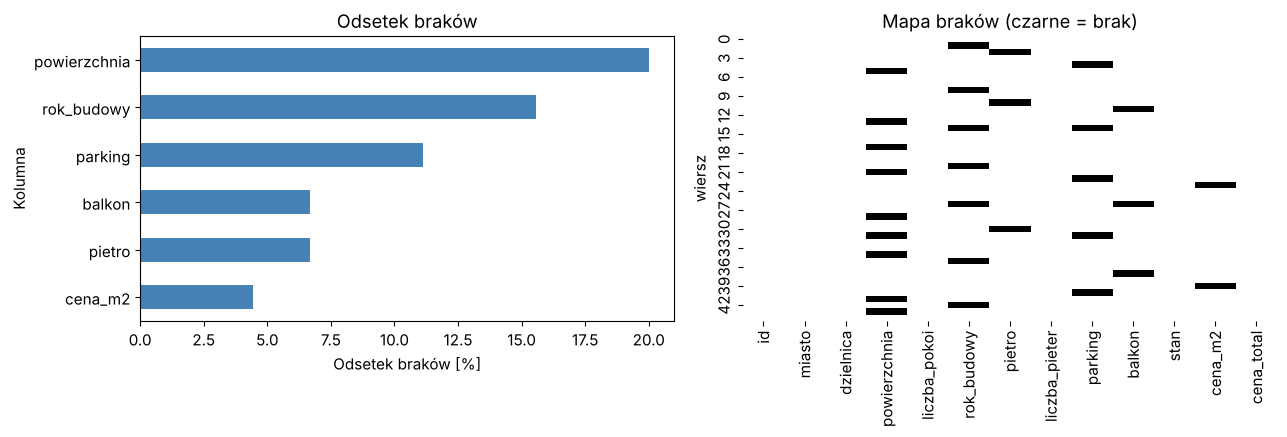

,powierzchnia,rok_budowy,pietro,parking,balkon,cena_m2
powierzchnia,1.00,-0.21,-0.13,-0.00,-0.13,-0.11
rok_budowy,-0.21,1.00,-0.11,0.04,0.13,-0.09
pietro,-0.13,-0.11,1.00,-0.09,-0.07,-0.06
parking,-0.00,0.04,-0.09,1.00,-0.09,-0.08
balkon,-0.13,0.13,-0.07,-0.09,1.00,-0.06
cena_m2,-0.11,-0.09,-0.06,-0.08,-0.06,1.00


Liczba braków w wierszu:
0    19
1    23
2     3
Name: count, dtype: int64


In [12]:
kol_braki = mieszkania.columns[mieszkania.isna().any()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
(mieszkania[kol_braki].isna().mean() * 100).sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set(xlabel="Odsetek braków [%]", ylabel="Kolumna", title="Odsetek braków")
sns.heatmap(mieszkania.isna(), cbar=False, cmap="Greys", ax=axes[1])
axes[1].set(title="Mapa braków (czarne = brak)", ylabel="wiersz")
plt.tight_layout()
plt.show()

korelacje = mieszkania[kol_braki].isna().astype(int).corr().round(2)
display(korelacje)

print("Liczba braków w wierszu:")
print(mieszkania.isna().sum(axis=1).value_counts().sort_index())

*Twoja odpowiedź:* Najwięcej braków ma `powierzchnia` (9, czyli 20%). Dalej są `rok_budowy` (7), `parking` (5), `pietro` (3), `balkon` (3) i `cena_m2` (2). Braki w różnych kolumnach **nie występują w tych samych wierszach**. Korelacje wskaźników braku są bliskie zera (wszystkie |r| ≤ 0,21), a żaden wiersz nie ma więcej niż 2 braków (19 wierszy kompletnych, 23 z jednym brakiem, 3 z dwoma). Wygląda to na niezależne, rozproszone braki, a nie na „puste” ogłoszenia. Dlatego usuwanie wierszy byłoby bardzo kosztowne: `dropna()` zostawiłoby tylko 19 z 45 ofert. Lepiej obsługiwać każdą kolumnę osobno.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [13]:
pelne = mieszkania.dropna(subset=["powierzchnia", "cena_m2"])
roznica = pelne["cena_total"] - pelne["powierzchnia"] * pelne["cena_m2"]
print(f"Wiersze z kompletem: {len(pelne)}, maks. |różnica|: {roznica.abs().max()}")
print("Zależność cena_total = powierzchnia × cena_m2 zachodzi:", np.allclose(roznica, 0))

braki_przed = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()

m_pow = mieszkania["powierzchnia"].isna() & mieszkania["cena_m2"].notna()
mieszkania.loc[m_pow, "powierzchnia"] = mieszkania.loc[m_pow, "cena_total"] / mieszkania.loc[m_pow, "cena_m2"]

m_cena = mieszkania["cena_m2"].isna() & mieszkania["powierzchnia"].notna()
mieszkania.loc[m_cena, "cena_m2"] = mieszkania.loc[m_cena, "cena_total"] / mieszkania.loc[m_cena, "powierzchnia"]

print("\nOdtworzone wiersze:")
display(mieszkania.loc[m_pow | m_cena, ["id", "powierzchnia", "cena_m2", "cena_total"]])

braki_po = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()
display(pd.DataFrame({"przed": braki_przed, "po": braki_po}))
print("Usunięto braków:", (braki_przed - braki_po).sum())

Wiersze z kompletem: 34, maks. |różnica|: 0.0
Zależność cena_total = powierzchnia × cena_m2 zachodzi: True

Odtworzone wiersze:


,id,powierzchnia,cena_m2,cena_total
5,6,80.0,15000.000000,1200000
13,14,60.0,10800.000000,648000
17,18,70.0,9200.000000,644000
21,22,60.0,9800.000000,588000
23,24,48.0,12500.000000,600000
28,29,60.0,10200.000000,612000
31,32,60.0,9400.000000,564000
34,35,80.0,8800.000000,704000
39,40,82.0,8895.121951,729400
41,42,60.0,9200.000000,552000


,przed,po
powierzchnia,9,0
cena_m2,2,0


Usunięto braków: 11


### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [14]:
# 1. Flagi braków — najpierw!
for kol in ["rok_budowy", "pietro", "parking", "balkon"]:
    mieszkania[f"{kol}_brak"] = mieszkania[kol].isna().astype(int)

# 2a. rok_budowy — porównanie median
print("Mediana całościowa:", mieszkania["rok_budowy"].median())
porownanie = pd.DataFrame({
    "mediana": mieszkania.groupby("stan")["rok_budowy"].median(),
    "min": mieszkania.groupby("stan")["rok_budowy"].min(),
    "max": mieszkania.groupby("stan")["rok_budowy"].max(),
})
print("\nRok budowy wg stanu:"); display(porownanie)
print("Rok budowy wg miasta:")
display(mieszkania.groupby("miasto")["rok_budowy"].agg(["median", "min", "max"]))
print("Wiersze z brakiem roku budowy:")
display(mieszkania.loc[mieszkania["rok_budowy"].isna(), ["id", "miasto", "stan", "cena_m2"]])

mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(
    mieszkania.groupby("stan")["rok_budowy"].transform("median")).round().astype(int)

# 2b. pietro — środkowe piętro budynku
print("Braki piętra:")
display(mieszkania.loc[mieszkania["pietro"].isna(), ["id", "pietro", "liczba_pieter"]])
print("Mediana całościowa piętra:", mieszkania["pietro"].median())
mieszkania["pietro"] = mieszkania["pietro"].fillna(mieszkania["liczba_pieter"] // 2).astype(int)
display(mieszkania.loc[mieszkania["pietro_brak"] == 1, ["id", "pietro", "liczba_pieter"]])

# 2c. parking, balkon — porównanie wariantów
for kol in ["parking", "balkon"]:
    dominanta = mieszkania[kol].mode()[0]
    warianty = pd.DataFrame({
        "tylko znane": mieszkania[kol].value_counts(normalize=True),
        f"dominanta ({dominanta})": mieszkania[kol].fillna(dominanta).value_counts(normalize=True),
        "\"nieznane\"": mieszkania[kol].fillna("nieznane").value_counts(normalize=True),
    }).mul(100).round(1)
    print(f"\n{kol} — rozkład [%]:"); display(warianty)
    mieszkania[kol] = mieszkania[kol].fillna("nieznane")

# 3. Kontrola
print("Pozostałe braki:", mieszkania.isna().sum().sum())
assert mieszkania.isna().sum().sum() == 0

Mediana całościowa: 2011.5

Rok budowy wg stanu:


,mediana,min,max
stan,,,
Bardzo dobry,2019.0,2017.0,2022.0
Do remontu,1997.0,1995.0,1999.0
Dobry,2010.0,2000.0,2016.0


Rok budowy wg miasta:


,median,min,max
miasto,,,
Gdańsk,2001.5,1997.0,2014.0
Kraków,2013.0,1995.0,2019.0
Poznań,2013.5,1996.0,2022.0
Warszawa,2015.0,2013.0,2020.0
Wrocław,2011.0,2006.0,2020.0


Wiersze z brakiem roku budowy:


,id,miasto,stan,cena_m2
1,2,Kraków,Bardzo dobry,10200.0
8,9,Poznań,Dobry,10500.0
14,15,Gdańsk,Dobry,8700.0
20,21,Warszawa,Bardzo dobry,12800.0
26,27,Kraków,Dobry,9600.0
35,36,Warszawa,Dobry,11200.0
42,43,Wrocław,Dobry,10000.0


... (5 outputs left out)

,tylko znane,dominanta (Tak),"""nieznane"""
parking,,,
Nie,15.0,13.3,13.3
Tak,85.0,86.7,75.6
nieznane,NaN,NaN,11.1



balkon — rozkład [%]:


,tylko znane,dominanta (Tak),"""nieznane"""
balkon,,,
Nie,16.7,15.6,15.6
Tak,83.3,84.4,77.8
nieznane,NaN,NaN,6.7


Pozostałe braki: 0


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

cena_m2          powierzchnia       rok_budowy        
            po    przed           po przed         po   przed
count     45.0     43.0         45.0  36.0       45.0    38.0
mean   10244.3  10223.3         64.9  64.6     2010.6  2010.3
std     1623.9   1611.7         12.8  13.7        7.4     7.8
min     8200.0   8200.0         42.0  42.0     1995.0  1995.0
25%     9000.0   9000.0         56.0  54.8     2006.0  2004.2
50%     9800.0   9800.0         62.0  63.0     2011.0  2011.5
75%    11200.0  11100.0         72.0  72.8     2017.0  2016.8
max    15000.0  15000.0         95.0  95.0     2022.0  2022.0

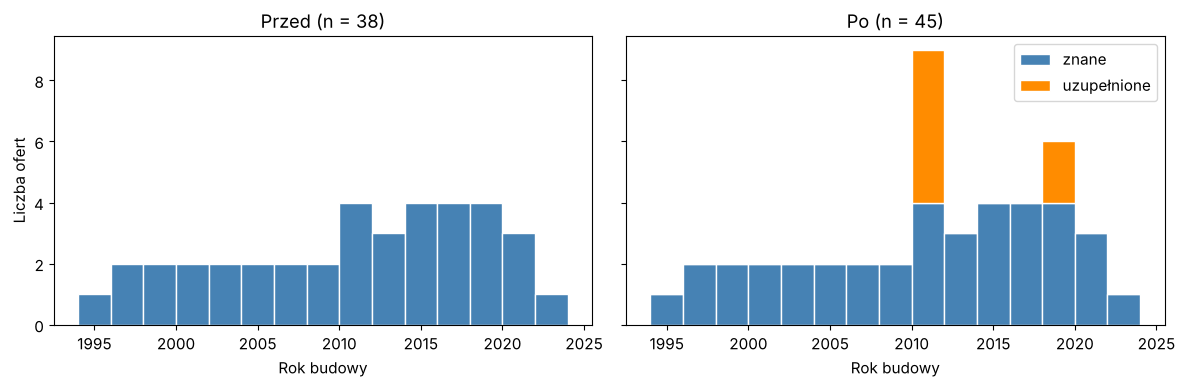

In [15]:
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
kolumny = ["powierzchnia", "rok_budowy", "cena_m2"]

porownanie = pd.concat({"przed": surowe[kolumny].describe(), "po": mieszkania[kolumny].describe()}, axis=1)
porownanie = porownanie.swaplevel(axis=1).sort_index(axis=1, level=0)
display(porownanie.round(1))

bins = np.arange(1994, 2025, 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].hist(surowe["rok_budowy"].dropna(), bins=bins, color="steelblue", edgecolor="white")
axes[0].set(title=f"Przed (n = {surowe['rok_budowy'].notna().sum()})", xlabel="Rok budowy", ylabel="Liczba ofert")
uzup = mieszkania["rok_budowy_brak"] == 1
axes[1].hist([mieszkania.loc[~uzup, "rok_budowy"], mieszkania.loc[uzup, "rok_budowy"]], bins=bins,
             stacked=True, color=["steelblue", "darkorange"], edgecolor="white", label=["znane", "uzupełnione"])
axes[1].set(title=f"Po (n = {len(mieszkania)})", xlabel="Rok budowy")
axes[1].legend()
plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Rozkłady nie zmieniły się istotnie.
- `cena_m2`: zmiana minimalna (średnia 10 223 → 10 244 zł). Odtworzono tylko 2 wartości i są to wartości prawdziwe, a nie szacunki.
- `powierzchnia`: średnia 64,6 → 64,9 m², mediana 63 → 62 m². Wszystkie 9 braków odtworzono dokładnie z ceny, więc to prawdziwy rozkład, a nie efekt imputacji. Wyraźnie widać jednak, że w odtworzonych wierszach często pojawia się 60 m².
- `rok_budowy`: średnia praktycznie bez zmian (2010,3 → 2010,6), odchylenie standardowe spadło lekko (7,8 → 7,4). Wstawiliśmy tylko 2 różne wartości (2010 dla stanu „Dobry”, 2019 dla „Bardzo dobry”), więc rozkład lekko „skupił się” wokół median grup, co widać na histogramie (pomarańczowe słupki). Przy 7 brakach na 45 ofert jest to efekt niewielki, ale trzeba o nim pamiętać, np. przy liczeniu wariancji.

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | `N/A`, `brak`, `0` | 9 (4 + 2 + 3) | Odtworzenie: `cena_total / cena_m2` | Zależność `cena_total = powierzchnia × cena_m2` zachodzi dokładnie we wszystkich 34 pełnych wierszach, więc znamy prawdziwą wartość. 0 m² jest niemożliwe, więc to brak. |
| `cena_m2` | `-1`, `-999` | 2 | Odtworzenie: `cena_total / powierzchnia` | Jak wyżej. Ujemna cena jest niemożliwa. Dla id 40 wynik nie jest okrągły (≈ 8 895 zł), ale wynika wprost z danych. |
| `rok_budowy` | `NA`, `brak` | 7 | Mediana w grupach wg `stan` + flaga `rok_budowy_brak` | Rok silnie zależy od stanu (przedziały się nie nakładają: do remontu 1995–1999, dobry 2000–2016, bardzo dobry 2017–2022). Miasta mają szerokie, nakładające się przedziały. Mediana całościowa (2011,5) ignoruje tę strukturę. |
| `pietro` | `brak`, `-999` (0 = parter, nie brak!) | 3 | `liczba_pieter // 2` + flaga `pietro_brak` | Gwarantuje sensowną wartość (≤ liczba pięter). Mediana całościowa (3) mogłaby przekroczyć wysokość niskiego budynku. |
| `parking` | `?` | 5 | Kategoria `"nieznane"` + flaga | Dominanta zawyżyłaby odsetek „Tak” (85% → 86,7%). Braków jest sporo (11%), a nie wiemy, czy brak informacji nie oznacza braku parkingu (możliwe MNAR). |
| `balkon` | `?` | 3 | Kategoria `"nieznane"` + flaga | Jak dla parkingu: nie fałszujemy proporcji i zachowujemy informację o braku. |
| `stan` | brak oznaczeń braków; jedna wartość `很好` | 0 (1 błędna wartość) | Zamiana `很好` → `Bardzo dobry` | `很好` to po chińsku „bardzo dobrze”. To błąd tłumaczenia lub kodowania, nie brak. Cena (10 200 zł/m²) jest zgodna z tą kategorią. |

### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [16]:
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
surowe["stan"] = surowe["stan"].replace({"很好": "Bardzo dobry"})
# cena_m2 odtwarzamy z ceny całkowitej (zad. 11), żeby korelacja liczyła się na pełnej kolumnie
surowe["cena_m2"] = surowe["cena_m2"].fillna(surowe["cena_total"] / surowe["powierzchnia"])

r = surowe["rok_budowy"]
warianty_roku = {
    "bez braków (tylko znane)": r,
    "mediana całościowa": r.fillna(r.median()),
    "mediana wg miasta": r.fillna(surowe.groupby("miasto")["rok_budowy"].transform("median")),
    "mediana wg stanu": r.fillna(surowe.groupby("stan")["rok_budowy"].transform("median")),
}
ref = r.corr(surowe["cena_m2"])  # pandas pomija pary z brakami
wyniki = pd.DataFrame({
    "korelacja z cena_m2": {k: v.corr(surowe["cena_m2"]) for k, v in warianty_roku.items()},
})
wyniki["różnica vs bez braków"] = wyniki["korelacja z cena_m2"] - ref
display(wyniki.round(3))

,korelacja z cena_m2,różnica vs bez braków
bez braków (tylko znane),0.709,0.000
mediana całościowa,0.678,-0.031
mediana wg miasta,0.710,0.001
mediana wg stanu,0.697,-0.011


*Twoja odpowiedź:* Korelacja `rok_budowy` z `cena_m2` na danych bez braków wynosi ok. 0,709.
- **Mediana całościowa** zaniża ją najbardziej (0,678; −0,031). Wstawia ten sam rok niezależnie od ceny, przez co „rozmywa” zależność.
- **Mediana wg miasta** praktycznie jej nie zmienia (0,710; +0,001). Wypada najlepiej w tym kryterium.
- **Mediana wg stanu** zmienia ją nieznacznie (0,697; −0,011).

Najmniej zmienia korelację mediana według miasta. Przy tylko 7 uzupełnianych wartościach różnice między wariantami grupowymi są jednak małe i mogą być przypadkowe. Mediana według stanu ma mocniejsze uzasadnienie merytoryczne, bo przedziały lat dla kategorii stanu się nie nakładają. Obie metody grupowe są wyraźnie lepsze od mediany całościowej. Wniosek: wybór metody ma znaczenie, a uzupełnianie jedną wartością dla wszystkich osłabia zależności między zmiennymi.